In [2]:
pip install pandas scikit-learn matplotlib

Depth=1, Train Accuracy=0.917, Test Accuracy=0.912
Depth=2, Train Accuracy=0.947, Test Accuracy=0.912
Depth=3, Train Accuracy=0.967, Test Accuracy=0.930
Depth=4, Train Accuracy=0.982, Test Accuracy=0.924
Depth=5, Train Accuracy=0.990, Test Accuracy=0.918
Depth=6, Train Accuracy=0.995, Test Accuracy=0.906
Depth=7, Train Accuracy=1.000, Test Accuracy=0.895
Depth=8, Train Accuracy=1.000, Test Accuracy=0.895
Depth=9, Train Accuracy=1.000, Test Accuracy=0.895
Depth=10, Train Accuracy=1.000, Test Accuracy=0.895
Depth=11, Train Accuracy=1.000, Test Accuracy=0.895
Depth=12, Train Accuracy=1.000, Test Accuracy=0.895
Depth=13, Train Accuracy=1.000, Test Accuracy=0.895
Depth=14, Train Accuracy=1.000, Test Accuracy=0.895
Depth=15, Train Accuracy=1.000, Test Accuracy=0.895


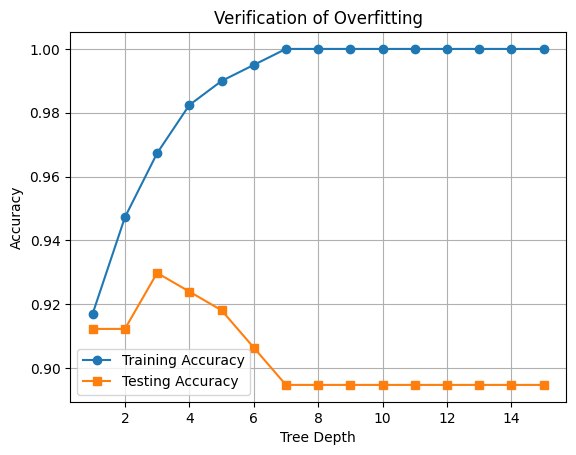

In [4]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Load dataset
df = pd.read_csv("/content/data-selected-columns.csv")

# Remove unnecessary columns
df = df.drop(columns=["id", "Unnamed: 32"], errors="ignore")

# Convert diagnosis into numerical values
df["diagnosis"] = df["diagnosis"].map({"M": 1, "B": 0})

# Separate features and target
X = df.drop("diagnosis", axis=1)
y = df["diagnosis"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

train_acc = []
test_acc = []
depths = range(1, 16)

# Train models with different depths
for depth in depths:
    model = DecisionTreeClassifier(
        max_depth=depth, random_state=42
    )
    model.fit(X_train, y_train)

    train_acc.append(
        accuracy_score(y_train, model.predict(X_train))
    )
    test_acc.append(
        accuracy_score(y_test, model.predict(X_test))
    )

# Display results
for d, tr, te in zip(depths, train_acc, test_acc):
    print(f"Depth={d}, Train Accuracy={tr:.3f}, "
          f"Test Accuracy={te:.3f}")

# Plot accuracy
plt.plot(depths, train_acc, marker="o",
         label="Training Accuracy")
plt.plot(depths, test_acc, marker="s",
         label="Testing Accuracy")

plt.xlabel("Tree Depth")
plt.ylabel("Accuracy")
plt.title("Verification of Overfitting")
plt.legend()
plt.grid(True)
plt.show()
